2025-10-20
This code takes the _MZdata datafiles (made from Jordan's sorting program and my Jupyter notebook) and makes a new file with the simple average activity score, DNA and AA sequences, and sequence properties.

1. Reads histograms and BC statistics are plotted
2. Simple average of activity is calculated, outliers (>2.6*standard deviation) are excluded and average is recalculated
3. Standardized activity is calculated from the controls library
4. delta is saved to .csv at a filepath.

In [19]:
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit

%load_ext autoreload
%autoreload 2

import sys
sys.path.append(r"C:\Users\music\Desktop\CompLab\Global_Scripts")
from Helpful import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# Edit these variables!

name = 'SynAD_Glu_sort2'
name_color = '#f598f5'

filetoprocess = r"..\..\data\labtools-processed\SynAD_Glu_2_allinfo.csv"
filetosave = rf"..\..\data\{name}_processed.csv"

excludedsaving = True
excludedtosave = rf"..\..\data\excluded\{name}_EXCLUDED.csv"

figsaving = True
if figsaving == True:
    readsfigpath = rf'..\..\output\ProcessingFigs\{name}_Reads_Distributions.png'
    standardizingfigpath = rf'..\..\output\ProcessingFigs\{name}_MachineGaussian.png'
    activityfigpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_Distribution.png'
    gcn4corrpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_Gcn4.png'
    stddevpath = rf'..\..\output\ProcessingFigs\{name}_StdActivity_corr_StdDev.png'

control_lib = True
if control_lib:
    ctrldesign = pd.read_csv(r'C:\Users\music\Desktop\CompLab\DesignFiles\Controls_Design_AA.csv')
    negdesign = pd.read_csv(r'C:\Users\music\Desktop\CompLab\DesignFiles\NegControls_Design_AA.csv')
    ctrldesign = ctrldesign[['AAseq']]
    negdesign = negdesign[['AAseq']]
    control_color = '#9ce799'
    gcn4sort=pd.read_csv(r"..\..\..\Global_Data\Gcn4OrthologData_MZorganized_20251021.csv")
    gcn4sort = gcn4sort[['AAseq', 'Ratio_Activity', 'Ratio_StdDev', 'GFP_Activity', 'GFP_StdDev', 'mCherry_Activity', 'mCherry_StdDev']]
    sort_type = 'Ratio'
    gcn4sim = pd.read_csv(r'..\..\..\DesignFiles\Gcn4similar_AAseq.csv')

In [21]:
ctrldesign

,AAseq
0,STIPLDFMPRDALHGFDWSEEDDMSDGLPFLKTDPNNNGF
1,STIPLDAMPRDALHGADASEEDDMSDGLPALKTDPNNNGA
2,STIPADFMPRDAAHGFDWSEEDDMSDGAPFAKTDPNNNGF
3,STDSTPMFEYENLEDNSKEWTSLFDNDIPVTTDDVSLADK
4,STDSTPMFEYENIEDNSKEWTSIFDNDIPVTTDDVSIADK
...,...
492,TTSSPPSGTHSSVSGVNSRKRDKPLPPIIVEDPNDTIAMK
493,RFYASSAPSSSAALNQQRQLAAHRPQVPLFSQSTGNNSNP
494,TPLAAPALERTVSSNTTKSSGSGSSVNSPIVMTNNSHRRK
495,TESCFLPTPIIEDAVLKPPKRSLTKRDADSVPASKSASPV


In [22]:
sort = pd.read_csv(filetoprocess,index_col=0)
sort

,DNAseq,AAseq,BC,Reads,0,1,2,3,4,5,6,7,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,CAATCTCCATTGTTGCCAGAAGAAGAATTGGAAGTTTCTGAACATT...,QSPLLPEEELEVSEHLRSNSSRRRSATTSSPPSGTHSSVS,GTCAAGATTCCATG,13439.0,12055.0,1363.0,1.0,1.0,16.0,2.0,0.0,1.0,3980.986753,1.0,38,114500.0
1,GTTCCATCTCCAGTTCCAGCTCCAGCTGTTGCTCCACAAGCTTCTC...,VPSPVPAPAVAPQASPVVASSPPPGASPRSGRNGRHSSVS,TTGCGACGCAGATT,2228.0,2076.0,75.0,0.0,24.0,53.0,0.0,0.0,0.0,5464.254323,1.0,37,89932.0
2,ATGCCATTTGATCCAACTGGTTTGGAAATTGCTGCTCCAGTTCCAG...,MPFDPTGLEIAAPVPAVKAEPTVSSPTVKPVSSPARSPTA,ACCCTAAAACAAGA,6983.0,5858.0,972.0,41.0,0.0,46.0,0.0,2.0,64.0,6795.417619,1.0,33,120569.0
3,GATCAAGAATTGTGGGAAGATTTGGATCCAACTATTTTGGTTTCTA...,DQELWEDLDPTILVSKLEDEDLRLGDKVLPNFEQVLTTNG,CGATTCGGTTAACC,9009.0,286.0,3303.0,3150.0,951.0,777.0,165.0,237.0,140.0,38910.457366,1.0,3,28903.0
4,AGAGGTTTGGAAAAATTGTTGGATTCTTCTAATCCAGAAATTATTG...,RGLEKLLDSSNPEIIDSVLEQSHEEFYFPSATDEEKRVME,TATGATTACCCTTA,10745.0,10182.0,125.0,100.0,40.0,298.0,0.0,0.0,0.0,5478.487928,1.0,3,33557.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61965,TTGAGAGTTCCATTGCCAGATTTGGGTACTGAATTGGATCATATTG...,LRVPLPDLGTELDHIDVLGIELGASFYDDNLFIGSDPLSS,TGTCTATTCTATCC,70.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.0,262143.000000,1.0,7,15259.0
61966,GAATTTTTGCAAGATCAATTTGATTTTTCTTTGCAAGCTTCTGGTT...,EFLQDQFDFSLQASGLEEMSIGYDYSSEFLSMPLLSDLEN,TGCAGCGGACCGTT,69.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,69.0,262143.000000,1.0,8,13713.0
61967,GGTCATAGATTTGATGTTTTGGTTACTTCTTTGTTGTATTTGGATT...,GHRFDVLVTSLLYLDLDLSWLESELFDSPLVPALNMEVVV,TGCAATAGGTCAAA,61.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,61.0,262143.000000,1.0,6,30375.0
61968,TTTATGGAAATTGCTTCTAATACTTTGGATGGTTTGATTTTGCCAG...,FMEIASNTLDGLILPEFLDLSDSLESPTESLDDFLDFLVS,CTTAGATCTAGGAC,76.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76.0,262143.000000,1.0,4,4938.0


### 1: Reads Figures

C:\Users\music\AppData\Local\Temp\ipykernel_62296\925139728.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sortsub.drop_duplicates(inplace=True)
C:\Users\music\AppData\Local\Temp\ipykernel_62296\925139728.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sortsub.drop_duplicates(inplace=True)


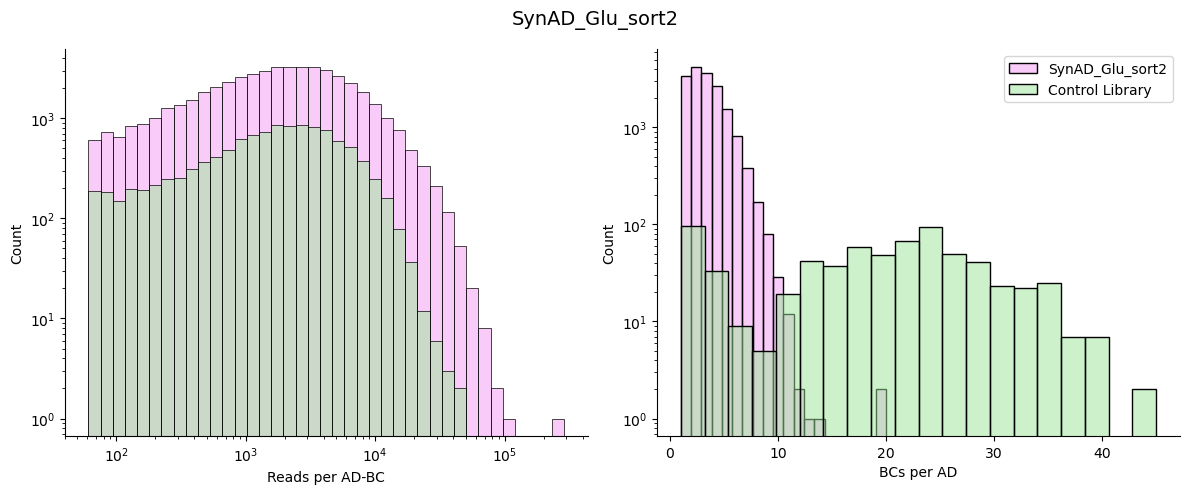

In [23]:
if control_lib:
    sort_ctrl = sort[sort['AAseq'].isin(ctrldesign['AAseq'])]
    sort_synad = sort[~sort['AAseq'].isin(ctrldesign['AAseq'])]
# Create figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Reads (log bins)
minp = sort['Reads'].min()
maxp = sort['Reads'].max()
log_bins = np.logspace(np.log10(minp), np.log10(maxp), 40)

if control_lib:
    sns.histplot(sort_synad['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=name_color, alpha=0.5, label=f'{name}')
    sns.histplot(sort_ctrl['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0], color=control_color, alpha=0.5, label='Control Library')
else:
    sns.histplot(sort['Reads'], bins=log_bins, edgecolor='black', linewidth=0.5, ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('Reads per AD-BC')
axes[0].set_ylabel('Count')
sns.despine(ax=axes[0])

# Plot 2: BCs per AD
sortsub = sort[['AAseq', 'ADs_per_BC', "BCs_per_AD"]]
sortsub.drop_duplicates(inplace=True)
if control_lib:
    sortsub = sort[['AAseq', 'ADs_per_BC', "BCs_per_AD"]]
    sortsub.drop_duplicates(inplace=True)
    sortsub_ctrl = sortsub[sortsub['AAseq'].isin(ctrldesign['AAseq'])]
    sortsub_synad = sortsub[~sortsub['AAseq'].isin(ctrldesign['AAseq'])]
    sns.histplot(sortsub_synad['BCs_per_AD'], bins=20, ax=axes[1], color=name_color, alpha=0.5, label=f'{name}')
    sns.histplot(sortsub_ctrl['BCs_per_AD'], bins=20, ax=axes[1], color=control_color, alpha=0.5, label='Control Library')
else:
    sns.histplot(sortsub['BCs_per_AD'], bins=20, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_xlabel('BCs per AD')
axes[1].set_ylabel('Count')
sns.despine(ax=axes[1])

if control_lib:
    plt.legend()
plt.suptitle(name, fontsize=14)
plt.tight_layout()
plt.show()

if figsaving:
    fig.savefig(readsfigpath, dpi=300)

### 2: Calculating Average Activity per AAseq

In [24]:
help(simple_average_minus_outliers)

Help on function simple_average_minus_outliers in module Helpful:

simple_average_minus_outliers(df, aa_col: str = 'AAseq', activity_col: str = 'Activity', min_reps_for_std: int = 2, ddof: int = 1, thresh: float = 2.6)
    Calculate simple averages per-group, remove outliers, and recompute.

    Minimal, explicit behavior:
    - Groups by `aa_col` and collects replicate values from `activity_col`.
    - Raises ValueError if any replicate value cannot be converted to float.
    - Uses `remove_outliers` with the provided `thresh` to decide exclusions.

    Returns (included_df, excluded_df) where included_df has one row per group and
    excluded_df has one row per original excluded replicate.



In [25]:
delta, excluded_df = simple_average_minus_outliers(sort, min_reps_for_std=2, ddof=1, thresh=2.6)
delta

,AAseq,Activity,StdDev,NumReps,OriginalIndices,ReplicateActivities
0,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,25075.335066,NaN,1,[29623],[25075.335066400457]
1,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,42928.146054,NaN,1,[24200],[42928.14605408071]
2,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,166188.911721,10690.676405,4,"[23403, 38324, 39020, 46787]","[163248.56079226287, 163910.340512013, 181356...."
3,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,108042.704031,12301.034795,4,"[29368, 39250, 48348, 48512]","[107680.62682752486, 96717.0143603506, 125227...."
4,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,56791.149738,NaN,1,[42019],[56791.14973759999]
...,...,...,...,...,...,...
17265,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,254373.309781,6573.017145,3,"[20998, 37820, 38677]","[250461.34568178095, 250696.6230975066, 261961..."
17266,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,237618.847801,32880.537293,3,"[29034, 53233, 61146]","[199926.91833088, 252512.77859266804, 260416.8..."
17267,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,46180.547181,NaN,1,[10164],[46180.54718142728]
17268,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,140773.532322,3425.556283,2,"[47984, 55735]","[138351.29824476107, 143195.76639835216]"


In [26]:
excluded_df

,AAseq,OriginalIndex,FilteredOutActivity,ReplicateActivities,SimpleAverageBefore,SimpleAverageAfter,SimpleStdDevBefore,SimpleStdDevAfter
0,AAIALSQPETIPAKEISVPPSPAVGKSASPAPSPAPSKSG,9157,14452.954643,"[6203.670311194044, 5997.860042374074, 3493.16...",5249.705605,4849.564343,2354.608160,1333.718962
1,AALDVALALSQPETKPAKEVSVPPSPAIRNSASPAPSPAP,7563,21924.781979,"[6222.337304406919, 3930.616659532553, 4509.18...",6212.280021,5244.617184,4679.021295,2019.113302
2,AALDVALALSQPETKPAKEVSVPPSPAIRNSASPAPSPAP,8834,26303.303024,"[6222.337304406919, 3930.616659532553, 4509.18...",6212.280021,5244.617184,4679.021295,2019.113302
3,ADPFSTSAQVALGTPDMDSTAMTPSMSRRSSSPGSSPKSG,4544,20555.869767,"[7421.70142563329, 8893.74024847999, 4782.9195...",6593.152582,5986.077922,3777.731612,2381.796572
4,ADVPAGTVSPSDLFMDASAPPSASFTDLSTPSFDSPGYFS,7095,4716.364037,"[67744.1175384442, 4716.364037057876, 104710.7...",75953.924869,79191.995815,22719.383281,16973.769592
...,...,...,...,...,...,...,...,...
356,YKMQQEQNMKTFDPEVAFEEWFLSTDYQGLPSDFSPLTGV,13451,158996.183043,"[158996.1830425272, 235859.8523299844, 251590....",244505.127530,248222.907725,20755.913056,10177.736998
357,YPSTPHPQPRLRVPVKATHRPSALQPFLAQNNPRRHSFNL,19009,31553.329597,"[6428.635372063018, 5313.117796372923, 6269.21...",8577.081534,6488.331710,7623.866890,2519.071274
358,YRSQSVSTQRRSATSGVRKRQPLPPIVVEDPSDTVAMKRA,4603,13616.166064,"[8422.08330355119, 5475.868307864209, 5442.932...",6447.616500,6106.256997,2621.698812,2127.254598
359,YSLFDSPSEGYETSPLFNTNDDLDDSNGWYSLFPPTTTSS,9982,3212.000000,"[3212.0, 205058.4673960771, 208652.23942624137...",193035.233485,202074.435079,49249.541077,25677.960176


### 5: Standardized activity

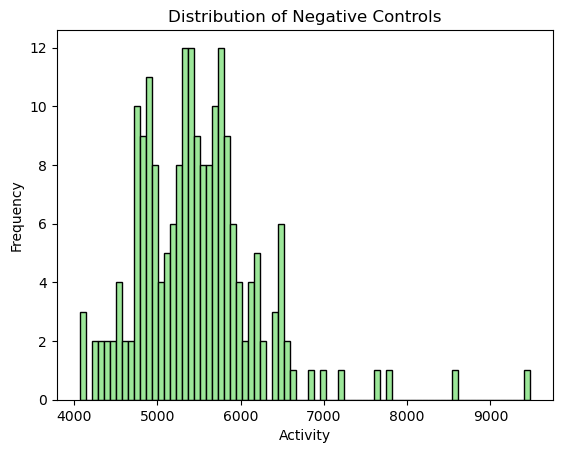

In [33]:
if control_lib:
    negctrls = delta[delta['AAseq'].isin(negdesign['AAseq'])]
    gcn4 = delta[delta['AAseq'] == 'STDSTPMFEYENLEDNSKEWTSLFDNDIPVTTDDVSLADK']['Activity'].values[0]
    gcn4s = delta[delta['AAseq'].isin(gcn4sim['AAseq'])]['Activity'].mean()

    plt.hist(data=negctrls, x="Activity",bins=75, edgecolor='black',linewidth=1, color=control_color)
    # Add labels and title
    plt.xlabel("Activity")
    plt.ylabel("Frequency")
    plt.title("Distribution of Negative Controls")
    # Show plot
    plt.show()
else:
    # Change this 'lowact' threshold until the machine noise peak is obvious
    lowact = delta['Activity'].quantile(0.03)
    lowdelta = delta[delta['Activity'] < lowact]

    plt.hist(data=lowdelta, x="Activity",bins=75, edgecolor='black',linewidth=1)
    # Add labels and title
    plt.xlabel("Activity")
    plt.ylabel("Frequency")
    plt.title("Distribution of Low Activity Sequences")
    # Show plot
    plt.show()

Gaussian equation: y = 17.83 * exp(-((x - 5390.12)^2) / (2 * 605.09^2))
Amplitude: 17.83
Mean: 5390.12
Standard deviation: 605.09


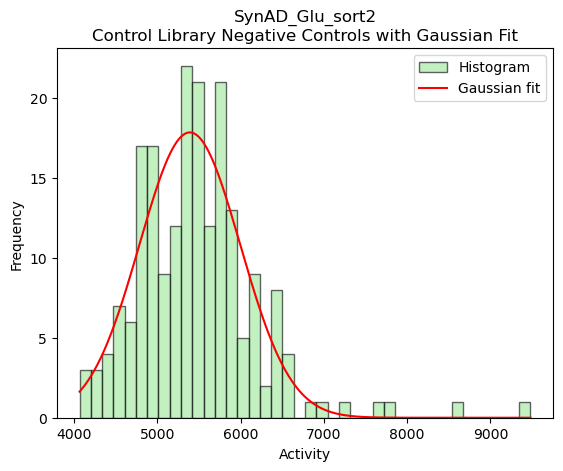

In [28]:
if control_lib:
    # Change variables
    numbins = 40

    # Define Gaussian function
    def gaussian(x, amp, mean, stdev):
        return amp * np.exp(-((x - mean) ** 2) / (2 * stdev ** 2))

    # Generate histogram data
    counts, bin_edges = np.histogram(negctrls['Activity'], bins=numbins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Fit Gaussian to histogram data
    popt, _ = curve_fit(gaussian, bin_centers, counts, p0=[1, 5000, 500])

    # Print the equation of the Gaussian
    amp, mean, stdev = popt
    print(f"Gaussian equation: y = {amp:.2f} * exp(-((x - {mean:.2f})^2) / (2 * {stdev:.2f}^2))\nAmplitude: {amp:.2f}\nMean: {mean:.2f}\nStandard deviation: {stdev:.2f}")

    # Plot histogram
    plt.hist(negctrls['Activity'], bins=numbins, edgecolor='black', linewidth=1, alpha=0.6, label='Histogram', color=control_color)

    # Plot Gaussian fit
    x_fit = np.linspace(bin_edges[0], bin_edges[-1], 1000)
    y_fit = gaussian(x_fit, *popt)
    plt.plot(x_fit, y_fit, color='red', label='Gaussian fit')

    # Add labels and title
    plt.xlabel("Activity")
    plt.ylabel("Frequency")
    plt.title(f"{name}\nControl Library Negative Controls with Gaussian Fit")
    plt.legend()
    if figsaving:
        plt.savefig(standardizingfigpath, dpi=300)
    # Show plot
    plt.show()
else:
    # Change variables
    numbins = 40

    # Define Gaussian function
    def gaussian(x, amp, mean, stdev):
        return amp * np.exp(-((x - mean) ** 2) / (2 * stdev ** 2))

    # Generate histogram data
    counts, bin_edges = np.histogram(lowdelta['Activity'], bins=numbins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Fit Gaussian to histogram data
    popt, _ = curve_fit(gaussian, bin_centers, counts, p0=[1, 5000, 500])

    # Print the equation of the Gaussian
    amp, mean, stdev = popt
    print(f"Gaussian equation: y = {amp:.2f} * exp(-((x - {mean:.2f})^2) / (2 * {stdev:.2f}^2))\nAmplitude: {amp:.2f}\nMean: {mean:.2f}\nStandard deviation: {stdev:.2f}")

    # Plot histogram
    plt.hist(lowdelta['Activity'], bins=numbins, edgecolor='black', linewidth=1, alpha=0.6, label='Histogram')

    # Plot Gaussian fit
    x_fit = np.linspace(bin_edges[0], bin_edges[-1], 1000)
    y_fit = gaussian(x_fit, *popt)
    plt.plot(x_fit, y_fit, color='red', label='Gaussian fit')

    # Add labels and title\
    plt.xlabel("Activity")
    plt.ylabel("Frequency")
    plt.title(f"{name}\nControl Library Negative Controls with Gaussian Fit")
    plt.legend()
    
    if figsaving:
        plt.savefig(standardizingfigpath, dpi=300)

    # Show plot
    plt.show()

SynAD_Glu_sort2: StdAct 0 = 5390.1 in FACS Activity; StdAct 1 (Gcn4) = 46954.4 in FACS Activity


C:\Users\music\AppData\Local\Temp\ipykernel_62296\2164408645.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


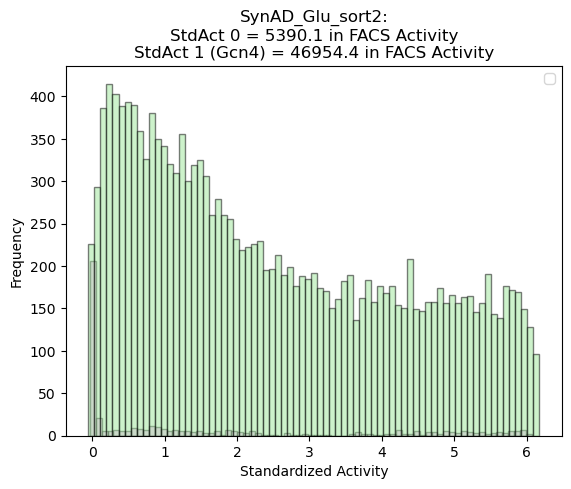

In [34]:
# Define the scaling function
def scale_activity(activity, min_val, max_val):
    return (activity - min_val) / (max_val - min_val)

# Define the min and max values
min_val = mean
max_val = gcn4s
print(f'{name}: StdAct 0 = {min_val:.1f} in FACS Activity; StdAct 1 (Gcn4) = {max_val:.1f} in FACS Activity')

# Apply the scaling function to the 'Activity' column
delta['StdActivity'] = delta['Activity'].apply(scale_activity, args=(min_val, max_val))
delta['ReplicateStdActivities'] = delta['ReplicateActivities'].apply(
    lambda activities: [scale_activity(activity, min_val, max_val) for activity in activities]
)

if control_lib:
    plt.hist(data=delta[delta['AAseq'].isin(ctrldesign['AAseq'])], x="StdActivity",bins=75, edgecolor='black',linewidth=1, alpha=0.5, color=name_color)
    plt.hist(data=delta[~delta['AAseq'].isin(ctrldesign['AAseq'])], x="StdActivity",bins=75, edgecolor='black',linewidth=1, alpha=0.5, color=control_color)
else:
    plt.hist(data=delta, x="StdActivity",bins=75, edgecolor='black',linewidth=1)

# Add labels and title
plt.xlabel("Standardized Activity")
plt.ylabel("Frequency")
plt.title(f"{name}:\nStdAct 0 = {min_val:.1f} in FACS Activity\nStdAct 1 (Gcn4) = {max_val:.1f} in FACS Activity")
if control_lib:
    plt.legend()
if figsaving:
    plt.savefig(activityfigpath, dpi=300)
# Show plot
plt.show()

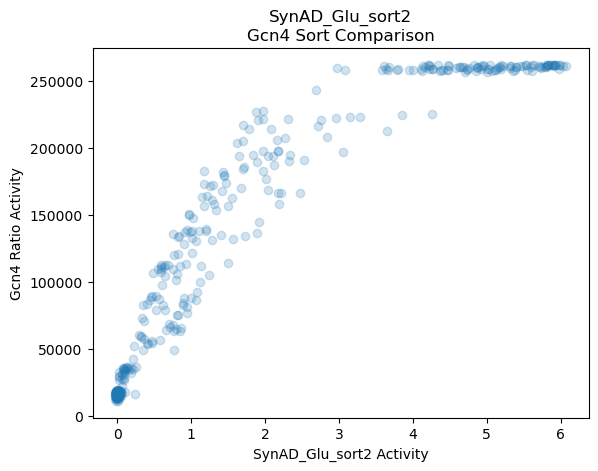

In [35]:
if control_lib:
    ctrls = delta[delta['AAseq'].isin(ctrldesign['AAseq'])]
    gcn4merge = pd.merge(ctrls, gcn4sort, on='AAseq', how='inner')
    plt.scatter(gcn4merge['StdActivity'], gcn4merge[f'{sort_type}_Activity'], alpha=0.2)
    plt.title(f'{name}\nGcn4 Sort Comparison')
    plt.xlabel(f'{name} Activity')
    plt.ylabel(f'Gcn4 {sort_type} Activity')
    if figsaving:
        plt.savefig(gcn4corrpath, dpi=300)
    plt.show()

In [36]:
# Define a function to calculate the standard deviation or return NaN
def calculate_stddev(activity_list):
    if len(activity_list) >= 2:
        return np.std(activity_list)
    else:
        return np.nan

# Apply the function to the 'ReplicateStdActivities' column
delta['StdActivityStdDev'] = delta['ReplicateStdActivities'].apply(calculate_stddev)

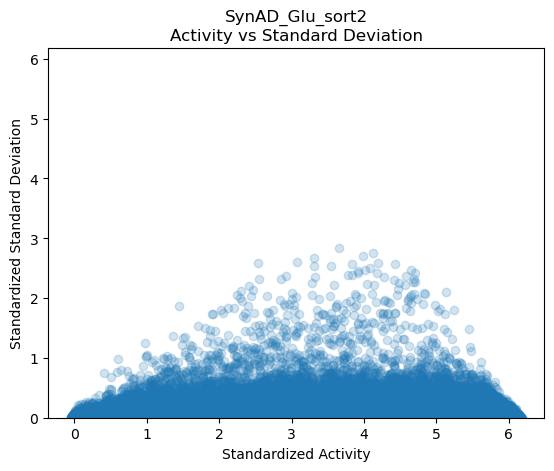

In [37]:
plt.scatter(delta['StdActivity'], delta['StdActivityStdDev'], alpha=0.2)
plt.ylim(0, max(delta['StdActivity']))
plt.title(f'{name}\nActivity vs Standard Deviation')
plt.xlabel('Standardized Activity')
plt.ylabel('Standardized Standard Deviation')
if figsaving:
    plt.savefig(stddevpath, dpi=300)
plt.show()

### 8: Saving data

In [38]:
delta.to_csv(filetosave)

In [39]:
if excludedsaving == True:
    excluded_df.to_csv(excludedtosave)

### 9: Extras

In [43]:
ctrls = delta[delta['AAseq'].isin(ctrldesign['AAseq'])]

In [44]:
ctrls.to_csv(r'C:\Users\music\Desktop\CompLab\Global_Data\CtrlsSynAD_stdact.csv', index=False)